In [2]:
import sys
from pathlib import Path

In [3]:
project_root = Path(r"C:\Users\cieci\OneDrive\Dokumenty\GitHub\Red-Scare-")

sys.path.insert(0, str(project_root / "src"))

print("Project root:", project_root)
print("Source folder exists:", (project_root / "src").exists())

Project root: C:\Users\cieci\OneDrive\Dokumenty\GitHub\Red-Scare-
Source folder exists: True


In [4]:
from runner import load_instance, draw

In [5]:
# example graph
g = load_instance("G-ex")

print("Start vertex:", g.s)
print("End vertex:", g.t)
print("Red vertices:", g.red)
print("Number of vertices:", g.graph.number_of_nodes())
print("Number of edges:", g.graph.number_of_edges())

Start vertex: 0
End vertex: 3
Red vertices: frozenset({'4', '5', '7'})
Number of vertices: 8
Number of edges: 9


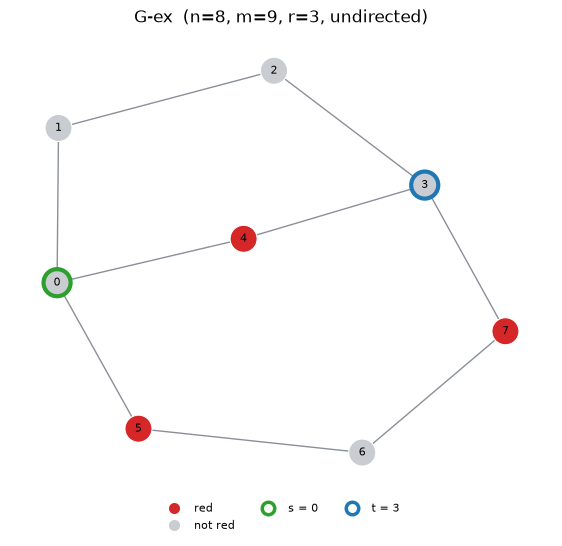

<Axes: title={'center': 'G-ex  (n=8, m=9, r=3, undirected)'}>

In [6]:
draw(g)

In [7]:
import networkx as nx

def solve(instance):
    graph = instance.graph.copy()
    s = instance.s
    t = instance.t
    red = instance.red

    # remove all red vertices from the graph (since the path should not contain any of them) except start and end
    red_to_remove = set(red) - {s, t}
    graph.remove_nodes_from(red_to_remove)

    # shortest path with BFS
    try:
        return nx.shortest_path_length(graph, source=s, target=t)

    except nx.NetworkXNoPath:
        return -1

In [8]:
answer = solve(g)

print("Shortest valid path length:", answer)

Shortest valid path length: 3


In [12]:
from runner import load_instances, run_experiment

graphs = load_instances()

print("Number of graphs loaded:", len(graphs))

Loading instances:   0%|          | 0/154 [00:00<?, ?file/s]

Number of graphs loaded: 154


In [13]:
results = run_experiment(
    solve,
    graphs,
    problem="none",
    timeout="5m",
    isolate=False
)

results.summary()

Running solve for problem 'none' on 154 instances · timeout not enforced (isolate=False) · started 22:21:51


  0%|                                                                                        | 0/154 [00:00<?,…

[22:21:51] ✓ bht  0.07s  answer=6
[22:21:51] ✓ common-1-20  <0.1ms  answer=-1
[22:21:51] ✓ common-2-20  <0.1ms  answer=-1
[22:21:51] ✓ common-1-50  0.3ms  answer=-1
[22:21:51] ✓ common-2-50  0.5ms  answer=-1
[22:21:51] ✓ common-1-100  0.9ms  answer=-1
[22:21:51] ✓ common-2-100  0.5ms  answer=-1
[22:21:51] ✓ common-1-250  0.8ms  answer=-1
[22:21:51] ✓ common-2-250  3.2ms  answer=-1
[22:21:51] ✓ common-1-500  2.2ms  answer=-1
[22:21:51] ✓ common-2-500  4.4ms  answer=4
[22:21:51] ✓ common-1-1000  5.2ms  answer=-1
[22:21:51] ✓ common-2-1000  0.02s  answer=4
[22:21:51] ✓ common-1-1500  6.5ms  answer=-1
[22:21:51] ✓ common-2-1500  0.04s  answer=4
[22:21:51] ✓ common-1-2000  8.4ms  answer=-1
[22:21:52] ✓ common-2-2000  0.08s  answer=4
[22:21:52] ✓ common-1-2500  0.02s  answer=6
[22:21:52] ✓ common-2-2500  0.10s  answer=4
[22:21:52] ✓ common-1-3000  0.02s  answer=6
[22:21:52] ✓ common-2-3000  0.14s  answer=4
[22:21:52] ✓ common-1-3500  0.02s  answer=6
[22:21:53] ✓ common-2-3500  0.23s  answer=